In [1]:
import numpy as np
import pandas as pd
import os
import matplotlib.pyplot as plt
import seaborn as sns
import RNA
import torch
import adabmDCA as dca

from annadca.rbm import get_rbm
from annadca.dataset import annaDataset

sns.set(style="whitegrid")
plt.rcParams.update({'font.size': 14,
                     'text.usetex': True})

device = torch.device("cuda" if torch.cuda.is_available() else "cpu")
dtype = torch.float32

In [2]:
tokens = dca.get_tokens("rna")
fname_data = "../data/SAM/SAM_all.csv"
dataset = annaDataset(
    path_data=fname_data,
    column_names="header",
    column_sequences="sequence",
    column_labels="label",
    alphabet=tokens,
    path_weights=None,
    no_reweighting=False,
    continuous_labels=True,
    is_binary=False,
    device=device,
    dtype=dtype,
)

Filtered out 0 sequences with unknown letters. Remaining sequences: 9693.


In [3]:
fname_RBM = "../models/SAM/binary_label_all/RBM_checkpoints/model_update_20000.pt"
fname_bmDCA = "../models/SAM/bmDCA/bmDCA_params.dat"
#fname_eaDCA = "../models/tRNA/eaDCA/aeDCA_params.dat"
#fname_edgeActDCA = "../models/tRNA/EdgeActivation/RF00005_model.dat"

gap_idx = tokens.index('-')
gap_field = -999.0

In [4]:
# Load the RBM model
checkpoint = torch.load(fname_RBM, map_location=device)
rbm = get_rbm(
    visible_type="potts",
    hidden_type="bernoulli",
    visible_shape=checkpoint["model_state_dict"]["weight_matrix"].shape[0:2],
    hidden_shape=checkpoint["model_state_dict"]["weight_matrix"].shape[2],
    num_classes=2,
    continuous_label=False,
)
rbm.load_state_dict(checkpoint["model_state_dict"])
rbm.to(device=device, dtype=dtype)

AnnaRBM(visible_layer=PottsLayer(shape=torch.Size([108, 5]), device=cuda:0, dtype=torch.float32), hidden_layer=BernoulliLayer(shape=torch.Size([500]), device=cuda:0, dtype=torch.float32), num_classes=torch.Size([2]), shape=torch.Size([108, 5, 500]))

In [5]:
# modify the visible biases to account for gaps-free generation
rbm.visible_layer.bias[:, gap_idx] = gap_field

ngen = 1000
nsteps = 10000

# Generate new sequences with the RBM
samples = rbm.sample(
    gibbs_steps=nsteps,
    num_samples=ngen,
)["visible"]

# count the number of gaps in each sequence
num_gapped_seqs = torch.any(samples.argmax(dim=-1) == gap_idx, dim=-1).sum().item()
print(f"Number of gapped sequences: {num_gapped_seqs} out of {ngen}")

W1013 15:03:15.280000 2017043 site-packages/torch/_inductor/utils.py:1436] [0/0] Not enough SMs to use max_autotune_gemm mode


Number of gapped sequences: 0 out of 1000


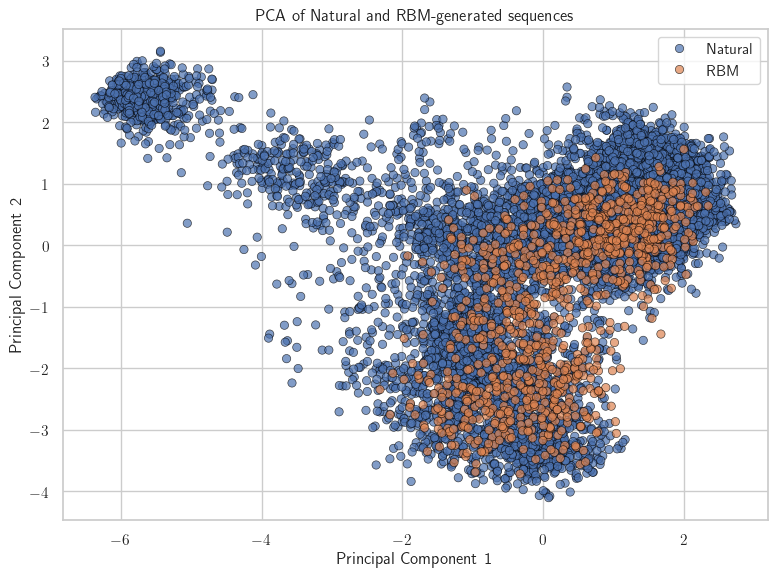

In [6]:
# visualize generated sequences on the data PCA
from sklearn.decomposition import PCA

pca = PCA(n_components=2)
data_pca = pca.fit_transform(dataset.data_one_hot.cpu().numpy().reshape(len(dataset), -1))
samples_pca = pca.transform(samples.cpu().numpy().reshape(len(samples), -1))

df1 = pd.DataFrame(data_pca, columns=["PC1", "PC2"])
df1["Type"] = "Natural"
df2 = pd.DataFrame(samples_pca, columns=["PC1", "PC2"])
df2["Type"] = "RBM"
df = pd.concat([df1, df2], ignore_index=True)

plt.figure(figsize=(8, 6))
sns.scatterplot(data=df, x="PC1", y="PC2", hue="Type", alpha=0.7, edgecolor='black')
plt.title("PCA of Natural and RBM-generated sequences")
plt.xlabel("Principal Component 1")
plt.ylabel("Principal Component 2")
plt.legend()
plt.grid(True)
plt.tight_layout()

In [11]:
# compute thermoscore
#dot_bracket_structure = "(((((((..((((.......)))).(((((.......)))))....(((((.......))))))))))))." # RF00005
dot_bracket_structure = "((((((((....(((((...(((.....)))......)))))((((.((((((.......))))..))))))...(....((((((.....))))))..)))))))))" #RF00162
RNA.cvar.temperature = 37


def compute_thermoscore(dot_bracket_structure, sequences_ART):
    tokens = dca.get_tokens("rna")
    sequences_RNA = ["".join(tokens[i] for i in sequence) for sequence in sequences_ART]
    thermoscores = []
    for sequence in sequences_RNA:
        fc = RNA.fold_compound(sequence)
        thermoscore = -fc.eval_structure(dot_bracket_structure)
        thermoscores.append(thermoscore)
    return thermoscores

thermoscores_gen = compute_thermoscore(dot_bracket_structure, samples.argmax(dim=-1).cpu().numpy())

In [12]:
from adabmDCA.statmech import compute_energy

In [13]:
energy_RBM = rbm.compute_energy_visibles(samples).cpu().numpy()
df2["Thermoscore"] = thermoscores_gen
df2["Energy_RBM"] = energy_RBM

for dca_model, fname_dca in zip(
    ["bmDCA",],
    [fname_bmDCA,],
):
    params_DCA = dca.load_params(fname_dca, tokens=tokens, device=device, dtype=dtype)
    energies_DCA = compute_energy(samples, params_DCA).cpu().numpy()
    df2[f"Energy_{dca_model}"] = energies_DCA

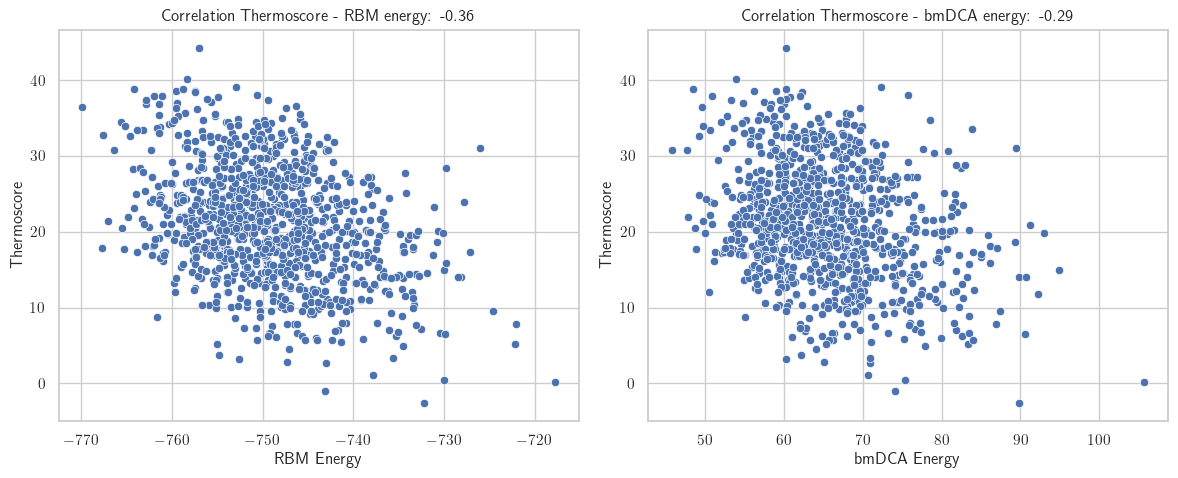

In [15]:
fig, axes = plt.subplots(1, 2, figsize=(12, 5))
axes = axes.flatten()
sns.scatterplot(data=df2, x="Energy_RBM", y="Thermoscore", ax=axes[0])
sns.scatterplot(data=df2, x="Energy_bmDCA", y="Thermoscore", ax=axes[1])
#sns.scatterplot(data=df2, x="Energy_eaDCA", y="Thermoscore", ax=axes[2])
#sns.scatterplot(data=df2, x="Energy_EdgeActivationDCA", y="Thermoscore", ax=axes[3])
for ax, model in zip(axes, ["RBM", "bmDCA",]):
    corrcoef = np.corrcoef(df2["Thermoscore"], df2[f"Energy_{model}"])[0, 1]
    ax.set_title(f"Correlation Thermoscore - {model} energy: {corrcoef:.2f}")
    ax.set_xlabel(f"{model} Energy")
    ax.set_ylabel("Thermoscore")
    ax.grid(True)
plt.tight_layout()